## Importation des biblio

In [22]:
import sys, platform
import torch, torchvision, cv2
import numpy as np
import pandas as pd
import matplotlib

## les versions

In [6]:
print("Python      :", sys.version.split()[0])


print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("CUDA (torch):", torch.version.cuda)
print("GPU dispo   :", torch.cuda.is_available())

Python      : 3.13.16
PyTorch     : 2.11.0+cu130
Torchvision : 0.26.0+cu130
CUDA (torch): 13.0
GPU dispo   : True


## Afficher etat de GPU

In [19]:
!nvidia-smi

Tue Oct 27 11:19:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8             15W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### graine alEatoire et fonction d’affichage

In [38]:
import os
import random
import shutil
import pathlib
import yaml
from collections import Counter
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
print("Device :", device)

def show(img, title=""):
    """Affiche une image OpenCV (BGR) avec Matplotlib (RGB)."""
    plt.figure(figsize=(7, 5))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title, fontsize=8)
    plt.axis("off")
    plt.show()

Device : cuda


## Télécharger le dataset depuis Kaggle

In [39]:
!pip install -q kagglehub
import kagglehub

dataset_path = pathlib.Path(
    kagglehub.dataset_download("ashfakyeafi/road-vehicle-images-dataset")
)
print("Dataset telechargE dans :", dataset_path)
print("Contenu :", os.listdir(dataset_path))

Using Colab cache for faster access to the 'road-vehicle-images-dataset' dataset.
Dataset telechargE dans : /kaggle/input/road-vehicle-images-dataset
Contenu : ['trafic_data']


## Exploration

## afficher l’arborescence du dataset

In [40]:
for root, dirs, files in os.walk(dataset_path):
    parts = pathlib.Path(root).relative_to(dataset_path).parts
    if len(parts) <= 4:
        print("  " * len(parts) + f"{os.path.basename(root)}/  ({len(files)} fichiers)")

road-vehicle-images-dataset/  (0 fichiers)
  trafic_data/  (1 fichiers)
    valid/  (1 fichiers)
      labels/  (300 fichiers)
      images/  (300 fichiers)
    train/  (1 fichiers)
      labels/  (2704 fichiers)
      images/  (2704 fichiers)


## Identifier les fichiers autre

In [41]:
SRC = dataset_path / "trafic_data" if (dataset_path / "trafic_data").is_dir() else dataset_path
print("Dossier source (lecture seule) :", SRC)

print("\nExtensions presentes :")
for ext, n in Counter(p.suffix.lower() for p in SRC.rglob("*") if p.is_file()).most_common():
    print(f"  {ext} : {n}")

print("\nFichiers hors images/labels :")
for folder in [SRC, SRC / "train", SRC / "valid"]:
    for f in folder.iterdir():
        if f.is_file():
            print(f"  {f.relative_to(SRC)}  ({f.stat().st_size / 1024:.1f} KB)")

Dossier source (lecture seule) : /kaggle/input/road-vehicle-images-dataset/trafic_data

Extensions présentes :
  .txt : 3004
  .jpg : 3004
  .cache : 2
  .yaml : 1

Fichiers hors images/labels :
  data_1.yaml  (0.3 KB)
  train/labels.cache  (1045.8 KB)
  valid/labels.cache  (118.9 KB)


### coper le dataset  sans cashe

In [42]:
WORK_DIR = pathlib.Path("/content/dataset")

if WORK_DIR.exists():
    shutil.rmtree(WORK_DIR)

shutil.copytree(SRC, WORK_DIR, ignore=shutil.ignore_patterns("*.cache"))
base_dir = WORK_DIR
splits = ["train", "valid"]

print("Copie cree dans :", base_dir)
for s in splits:
    n_img = len(list((base_dir / s / "images").iterdir()))
    n_lbl = len(list((base_dir / s / "labels").iterdir()))
    print(f"{s}: {n_img} images | {n_lbl} labels")

Copie cree dans : /content/dataset
train: 2704 images | 2704 labels
valid: 300 images | 300 labels


### verifier  images / labels

In [43]:
def check_split(base_dir, split):
    img_dir = base_dir / split / "images"
    lbl_dir = base_dir / split / "labels"

    img_stems = {f.stem: f for f in img_dir.iterdir() if f.suffix.lower() in IMG_EXT}
    lbl_stems = {f.stem: f for f in lbl_dir.iterdir() if f.suffix == ".txt"}

    labels_sans_image = sorted(set(lbl_stems) - set(img_stems))
    images_sans_label = sorted(set(img_stems) - set(lbl_stems))
    labels_vides = sorted(s for s, f in lbl_stems.items() if f.stat().st_size == 0)

    print(f" {split}")
    print(f"Images            : {len(img_stems)}")
    print(f"Labels            : {len(lbl_stems)}")
    print(f"Labels sans image : {len(labels_sans_image)}")
    print(f"Images sans label : {len(images_sans_label)}")
    print(f"Labels vides      : {len(labels_vides)}")
    return labels_sans_image, images_sans_label, labels_vides

results = {s: check_split(base_dir, s) for s in splits}

 train
Images            : 2704
Labels            : 2704
Labels sans image : 0
Images sans label : 0
Labels vides      : 2
 valid
Images            : 300
Labels            : 300
Labels sans image : 0
Images sans label : 0
Labels vides      : 0


##les labels vides

Labels vides (train) : ['01_jpg.rf.8d8a2f0f90d5b83893cd252acd832c93', '231_jpg.rf.42292592b7fed42abf94d9624eda3fa5']


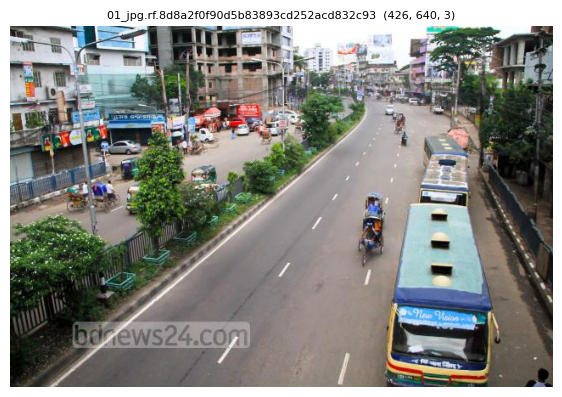

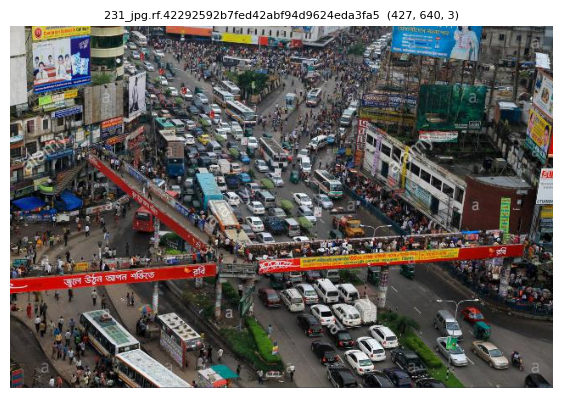

In [44]:
_, _, vides_train = results["train"]
print("Labels vides (train) :", vides_train)

for stem in vides_train:
    img_path = next(f for f in (base_dir / "train" / "images").iterdir()
                    if f.stem == stem and f.suffix.lower() in IMG_EXT)
    img = cv2.imread(str(img_path))
    show(img, f"{stem}  {img.shape}")

### Supprimer les labels vides et leurs images

In [45]:
removed = []
for split in splits:
    lbl_dir = base_dir / split / "labels"
    img_dir = base_dir / split / "images"
    for lbl in lbl_dir.glob("*.txt"):
        if lbl.stat().st_size == 0:
            for img in img_dir.iterdir():
                if img.stem == lbl.stem and img.suffix.lower() in IMG_EXT:
                    img.unlink()
            lbl.unlink()
            removed.append((split, lbl.stem))

print(f"{len(removed)} paires (image + label) supprimées :")
for split, stem in removed:
    print("  ", split, stem)

2 paires (image + label) supprimées :
   train 231_jpg.rf.42292592b7fed42abf94d9624eda3fa5
   train 01_jpg.rf.8d8a2f0f90d5b83893cd252acd832c93


## Vérifier le résultat



In [47]:
for split in splits:
    imgs = [f for f in (base_dir / split / "images").iterdir() if f.suffix.lower() in IMG_EXT]
    lbls = list((base_dir / split / "labels").glob("*.txt"))
    vides = [f for f in lbls if f.stat().st_size == 0]
    print(f"{split}: {len(imgs)} images | {len(lbls)} labels | {len(vides)} vides")

train: 2702 images | 2702 labels | 0 vides
valid: 300 images | 300 labels | 0 vides


### Lire le fichier de configuration

In [48]:
cfg_path = base_dir / "data_1.yaml"
with open(cfg_path) as f:
    cfg = yaml.safe_load(f)

print(yaml.dump(cfg, allow_unicode=True))
names = cfg["names"]
names_list = list(names.values()) if isinstance(names, dict) else list(names)
print("Nombre de classes (nc) :", cfg.get("nc"))
print("Nombre de noms         :", len(names_list))
print("Classes                :", names_list)
assert cfg.get("nc", len(names_list)) == len(names_list), "nc ne correspond pas a names "

names:
- ambulance
- army vehicle
- auto rickshaw
- bicycle
- bus
- car
- garbagevan
- human hauler
- minibus
- minivan
- motorbike
- pickup
- policecar
- rickshaw
- scooter
- suv
- taxi
- three wheelers -CNG-
- truck
- van
- wheelbarrow
nc: 21
train: ../train/images
val: ../valid/images

Nombre de classes (nc) : 21
Nombre de noms         : 21
Classes                : ['ambulance', 'army vehicle', 'auto rickshaw', 'bicycle', 'bus', 'car', 'garbagevan', 'human hauler', 'minibus', 'minivan', 'motorbike', 'pickup', 'policecar', 'rickshaw', 'scooter', 'suv', 'taxi', 'three wheelers -CNG-', 'truck', 'van', 'wheelbarrow']


### data.yaml avec des chemins corrects

In [49]:
data_yaml = {
    "path": str(base_dir),
    "train": "train/images",
    "val": "valid/images",
    "nc": len(names_list),
    "names": names_list,
}

DATA_YAML = base_dir / "data.yaml"
with open(DATA_YAML, "w") as f:
    yaml.safe_dump(data_yaml, f, allow_unicode=True, sort_keys=False)

print("Fichier ecrit :", DATA_YAML)
print(DATA_YAML.read_text())

Fichier écrit : /content/dataset/data.yaml
path: /content/dataset
train: train/images
val: valid/images
nc: 21
names:
- ambulance
- army vehicle
- auto rickshaw
- bicycle
- bus
- car
- garbagevan
- human hauler
- minibus
- minivan
- motorbike
- pickup
- policecar
- rickshaw
- scooter
- suv
- taxi
- three wheelers -CNG-
- truck
- van
- wheelbarrow



### Preparation de YOLOv9

In [50]:
%cd /content
!git clone https://github.com/WongKinYiu/yolov9.git
%cd /content/yolov9
!pip install -q -r requirements.txt

/content
Cloning into 'yolov9'...
remote: Enumerating objects: 781, done.
remote: Total 781 (delta 0), reused 0 (delta 0), pack-reused 781 (from 1)
Receiving objects: 100% (781/781), 3.27 MiB | 29.63 MiB/s, done.
Resolving deltas: 100% (330/330), done.
/content/yolov9


### fichiers de configuration